In [1]:
# Análisis de comentarios de experiencia
import warnings; warnings.filterwarnings("ignore")
import re
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

SEED    = 42
DATA_DIR = Path("../data")
OUT_DIR  = Path("../outputs")
FIG_DIR  = Path("../figures")

print("Config OK")

Config OK


In [2]:
STOPWORDS_ES = set("""
a al algo algunas algunos ante antes como con contra cual cuando de del desde
donde durante e el ella ellas ellos en entre era eres es esa esas ese eso esos
esta estas este esto estos fue fui ha había han hasta he hemos hice hizo
la las le les lo los me mi mio mis mismo más no nos nuestra nuestro nuestros
o para pero poco por porque que quien se si sin sino sobre su sus también te
tengo ti todo todos tu tus un una uno unos usted va ve voy y ya yo
aquí ahí allí bien mal muy poco mucho menos más hay haber ser estar tener hacer
ir ver dar saber poder querer decir venir llevar pasar otro otra otros otras
mismo misma mismas estos estas aquellos aquellas ese esa esos esas
sin con por para ante bajo cabe con contra de desde durante en entre hacia
hasta mediante para por según sin sobre tras
fue ser estar tener haber hacer poder querer saber ir ver dar venir llevar
pasar ningún ninguna primer primera algunos algunas todo toda todos todas
pues bien mal así como si aunque cuando porque mientras que
fue era eran fueron era eras éramos
les los las me te se nos os
hola gracias buenas buenos dias tardes noches señor señora señorita
""".split())

STOPWORDS_SEGUROS = set([
    "póliza","poliza","seguro","seguros","cliente","clientes",
    "aseguradora","compañía","compania","empresa",
    "servicio","servicios","atención","atencion",
    "llamada","call","center","asesor","asesora","asesores",
])
STOPWORDS_ALL = STOPWORDS_ES | STOPWORDS_SEGUROS

EMOJI_PAT = re.compile(
    "[\U00010000-\U0010ffff\U0001F600-\U0001F64F"
    "\U0001F300-\U0001F5FF\U0001F680-\U0001F9FF]+",
    flags=re.UNICODE)

def clean_text(txt):
    if not isinstance(txt, str): return ""
    txt = txt.lower()
    txt = EMOJI_PAT.sub(" ", txt)
    txt = re.sub(r"http\S+|www\.\S+", " ", txt)
    txt = re.sub(r"[^a-záéíóúüñ\s]", " ", txt)
    txt = re.sub(r"\s+", " ", txt).strip()
    tokens = [t for t in txt.split() if t not in STOPWORDS_ALL and len(t) > 2]
    return " ".join(tokens)

print("Función de limpieza OK")

Función de limpieza OK


In [3]:
exp = pd.read_csv(DATA_DIR / "experiencia.csv", parse_dates=["fecha_medicion"])
print(f"experiencia.csv: {exp.shape}")

NONE_VALUES = {"none","nan","no comment","n/a","","na","ninguno","ninguna","sin comentario"}
mask_real = (
    exp["comentario"].notna() &
    ~exp["comentario"].str.strip().str.lower().isin(NONE_VALUES) &
    (exp["comentario"].str.len() >= 5)
)
df = exp[mask_real].copy().reset_index(drop=True)
print(f"Con comentario real: {len(df):,} / {len(exp):,} ({len(df)/len(exp)*100:.1f}%)")

df["texto_limpio"] = df["comentario"].apply(clean_text)
df = df[df["texto_limpio"].str.strip() != ""].reset_index(drop=True)
print(f"Después de limpieza: {len(df):,} comentarios")

experiencia.csv: (99775, 10)
Con comentario real: 86,429 / 99,775 (86.6%)
Después de limpieza: 76,581 comentarios


In [4]:
POSITIVOS = set(
    "excelente rapido rapida amable amables eficiente eficaz bueno buena muy bien "
    "perfecto perfecta soluciono solucionó resolvió resolvio ayudo ayudó facil fácil "
    "genial increible increíble maravilloso agradable satisfecho satisfecha contento "
    "contenta agradecido agradecida feliz gracias espectacular recomiendo rápido".split())

NEGATIVOS = set(
    "malo mala pesimo pésima terrible horrible demora demorar cobro mal cobrado "
    "negaron negado preexistencia morosidad mora cobraron doble "
    "decepcionado decepcionada decepcionante incumplieron incumplió engaño engañaron "
    "mentira mentiras fraude estafar estafaron difícil difícilmente complicado complicada "
    "negativo negativa nunca imposible rechazaron rechazo nunca jamás "
    "cobro doble retraso retrasos demora demoras devolución".split())

def sentimiento_texto(texto):
    tokens = set(texto.split())
    pos = len(tokens & POSITIVOS)
    neg = len(tokens & NEGATIVOS)
    if pos > neg: return 1
    elif neg > pos: return -1
    return 0

def sentimiento_combinado(row):
    score = 0.0
    if pd.notna(row["nps"]):
        score += (min(row["nps"], 10) - 5) / 5 * 0.6
    if pd.notna(row["satisfaccion"]):
        score += (row["satisfaccion"] - 3) / 2 * 0.3
    score += row["sent_texto"] * 0.1
    if score > 0.15:  return "Positivo"
    elif score < -0.15: return "Negativo"
    return "Neutro"

df["sent_texto"] = df["texto_limpio"].apply(sentimiento_texto)
df["sentimiento"] = df.apply(sentimiento_combinado, axis=1)

print("Distribución de sentimiento:")
print(df["sentimiento"].value_counts().to_string())
print()
print(df["sentimiento"].value_counts(normalize=True).mul(100).round(1).to_string())

Distribución de sentimiento:
sentimiento
Positivo    48045
Negativo    14541
Neutro      13995

sentimiento
Positivo    62.7
Negativo    19.0
Neutro      18.3


In [5]:
N_TOPICS = 8

vec = CountVectorizer(
    max_features=3000,
    min_df=10,
    max_df=0.85,
    ngram_range=(1, 2),
)
dtm = vec.fit_transform(df["texto_limpio"])
print(f"DTM: {dtm.shape[0]:,} docs × {dtm.shape[1]:,} términos")

lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=SEED,
    learning_method="online",
    max_iter=20,
    n_jobs=-1,
)
doc_topics = lda.fit_transform(dtm)
print(f"Perplexity: {lda.perplexity(dtm):.1f}")

feature_names = vec.get_feature_names_out()
print("\n── Top 12 palabras por tema ──")
for idx, topic in enumerate(lda.components_):
    top_idx = topic.argsort()[-12:][::-1]
    words = [feature_names[i] for i in top_idx]
    print(f"  T{idx}: {', '.join(words)}")

DTM: 76,581 docs × 3,000 términos
Perplexity: 758.6

── Top 12 palabras por tema ──
  T0: buena, excelente, contenta, cancelo, aplicación, soluciona, soluciona cancelo, cita, contestaron, solucionaron, veces, recomendados
  T1: hace, años, descuento, soy, hace años, anual, deberían, precio, soy hace, qué, buen, cómo
  T2: momento, excelente, plan, buena, ayudó, resaltar, pendiente, llegó, felicito, quiero, estuvo, quiero resaltar
  T3: reembolso, pagaron, vez, nadie, pasa, vez pasa, semana, días, pocos, cobraron, asegurada, familia
  T4: atento, mui, quedo, estoy, retirar, evaluando, estoy evaluando, evaluando retirar, atenta, pólizas, siempre, atendieron
  T5: app, celular, fácil, pagar, autorización, llamar, perfecto, ustedes, nunca, momento, pague, dios
  T6: ahora, nada, estoy, quisiera, cambio, solo, comentario, ninguno, competencia, renovación, año, trasladarme
  T7: autorizaron, ustedes, cancelar, línea, apenas, problema, venza, llega, apenas venza, cancelar apenas, día, paga


In [6]:
# Etiquetas derivadas de la exploración de top-words
TOPIC_LABELS = {
    0: "Cancelación_y_NoRenovación",
    1: "Reembolsos",
    2: "Autorización_y_Cobertura",
    3: "Experiencia_Positiva",
    4: "Cobro_y_Facturación",
    5: "App_y_Canales_Digitales",
    6: "Renovación_y_Siniestros",
    7: "Propuesta_Comercial",
}

df["id_tema"]     = doc_topics.argmax(axis=1)
df["nombre_tema"] = df["id_tema"].map(TOPIC_LABELS)
df["prob_tema"]   = doc_topics.max(axis=1)

print("Distribución de temas:")
dist = df["nombre_tema"].value_counts()
for name, cnt in dist.items():
    print(f"  {name:<40} {cnt:>6,}  ({cnt/len(df)*100:.1f}%)")

Distribución de temas:
  Renovación_y_Siniestros                  15,033  (19.6%)
  Autorización_y_Cobertura                 11,762  (15.4%)
  App_y_Canales_Digitales                  10,891  (14.2%)
  Reembolsos                                9,425  (12.3%)
  Cancelación_y_NoRenovación                9,006  (11.8%)
  Propuesta_Comercial                       7,494  (9.8%)
  Cobro_y_Facturación                       6,742  (8.8%)
  Experiencia_Positiva                      6,228  (8.1%)


In [7]:
def priority_score(row):
    s = 0.0
    s += 2.0 if row["sentimiento"] == "Negativo" else (0.5 if row["sentimiento"] == "Neutro" else 0)
    if pd.notna(row["nps"]) and row["nps"] <= 6:
        s += 1.0
    if pd.notna(row["esfuerzo"]) and row["esfuerzo"] <= 2:
        s += 1.0
    if row.get("punto_contacto") == "Presencial":
        s += 0.5
    return round(s, 2)

df["puntaje_prioridad"] = df.apply(priority_score, axis=1)
df["prioridad"] = pd.cut(
    df["puntaje_prioridad"],
    bins=[0, 0.5, 2.0, 4.5],
    labels=["Baja", "Media", "Alta"],
    include_lowest=True
)

print("Prioridad:")
print(df["prioridad"].value_counts().to_string())
print()
n_alta = (df["prioridad"] == "Alta").sum()
print(f"Alta prioridad: {n_alta:,} ({n_alta/len(df)*100:.1f}%)")
print("Temas más críticos:")
print(df[df["prioridad"]=="Alta"]["nombre_tema"].value_counts().head(5).to_string())

Prioridad:
prioridad
Baja     44711
Alta     17762
Media    14108

Alta prioridad: 17,762 (23.2%)
Temas más críticos:
nombre_tema
Renovación_y_Siniestros       3465
Propuesta_Comercial           2450
App_y_Canales_Digitales       2320
Reembolsos                    2191
Cancelación_y_NoRenovación    2060


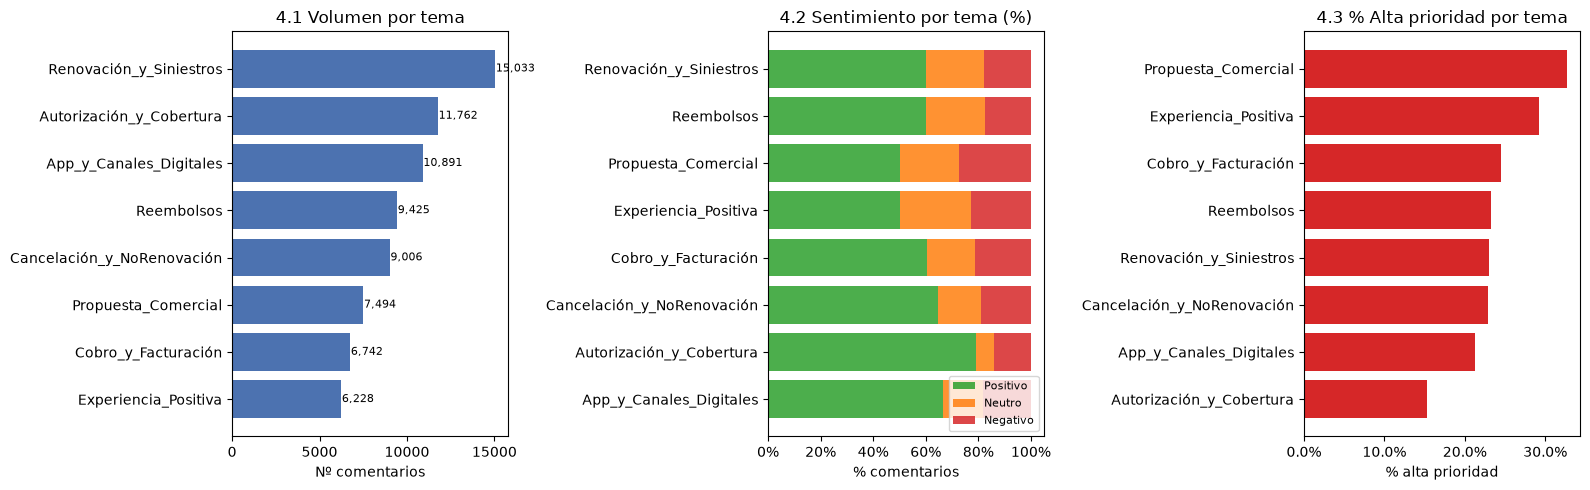

Figura 4.1 guardada


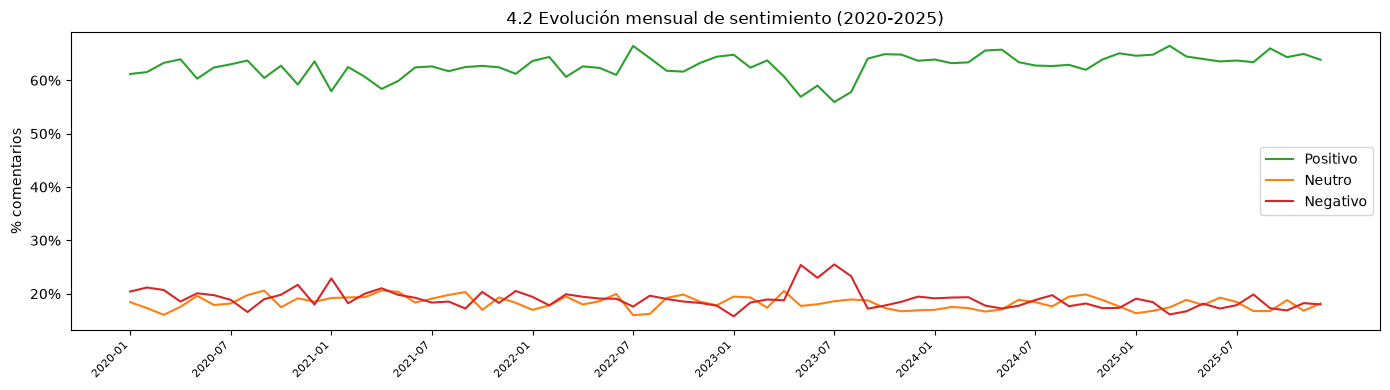

Figura 4.2 guardada


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 4.1 Volumen por tema
topic_counts = df["nombre_tema"].value_counts()
axes[0].barh(topic_counts.index[::-1], topic_counts.values[::-1], color="#4C72B0")
axes[0].set_xlabel("Nº comentarios")
axes[0].set_title("4.1 Volumen por tema")
for i, v in enumerate(topic_counts.values[::-1]):
    axes[0].text(v + 50, i, f"{v:,}", va="center", fontsize=8)

# 4.2 Sentimiento por tema (barras apiladas)
sent_pivot = df.groupby(["nombre_tema","sentimiento"]).size().unstack(fill_value=0)
sent_pct   = sent_pivot.div(sent_pivot.sum(axis=1), axis=0) * 100
colors_s   = {"Positivo": "#2ca02c", "Neutro": "#ff7f0e", "Negativo": "#d62728"}
bottom = np.zeros(len(sent_pct))
for col in ["Positivo", "Neutro", "Negativo"]:
    if col in sent_pct.columns:
        vals = sent_pct[col].values
        axes[1].barh(sent_pct.index, vals, left=bottom,
                     label=col, color=colors_s[col], alpha=0.85)
        bottom += vals
axes[1].set_xlabel("% comentarios")
axes[1].set_title("4.2 Sentimiento por tema (%)")
axes[1].legend(loc="lower right", fontsize=8)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter())

# 4.3 % Alta prioridad por tema
alt_pct = (df[df["prioridad"]=="Alta"].groupby("nombre_tema").size() /
           df.groupby("nombre_tema").size() * 100).sort_values(ascending=False)
axes[2].barh(alt_pct.index[::-1], alt_pct.values[::-1], color="#d62728")
axes[2].set_xlabel("% alta prioridad")
axes[2].set_title("4.3 % Alta prioridad por tema")
axes[2].xaxis.set_major_formatter(mtick.PercentFormatter())

plt.tight_layout()
plt.savefig(FIG_DIR / "4_1_temas_sentimiento_prioridad.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura 4.1 guardada")

# Figura 4.2 — Evolución mensual
df["anio_mes"] = df["fecha_medicion"].dt.to_period("M")
evol = (df.groupby(["anio_mes","sentimiento"])
          .size().unstack(fill_value=0)
          .assign(total=lambda x: x.sum(axis=1)))
for col in ["Positivo","Neutro","Negativo"]:
    if col in evol.columns:
        evol[col+"_pct"] = evol[col] / evol["total"] * 100

fig2, ax2 = plt.subplots(figsize=(14, 4))
months = [str(p) for p in evol.index]
x = list(range(len(months)))
for col, color in [("Positivo","#2ca02c"),("Neutro","#ff7f0e"),("Negativo","#d62728")]:
    col_p = col + "_pct"
    if col_p in evol.columns:
        ax2.plot(x, evol[col_p], label=col, color=color, linewidth=1.5)
ax2.set_xticks(x[::6])
ax2.set_xticklabels(months[::6], rotation=45, ha="right", fontsize=8)
ax2.set_ylabel("% comentarios")
ax2.set_title("4.2 Evolución mensual de sentimiento (2020-2025)")
ax2.legend()
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout()
plt.savefig(FIG_DIR / "4_2_evolucion_sentimiento.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figura 4.2 guardada")

In [9]:
OUT_COLS = [
    "id_respuesta","tipo_documento","numero_documento",
    "fecha_medicion","tipo_medicion","punto_contacto",
    "nps","satisfaccion","esfuerzo",
    "comentario","texto_limpio",
    "sentimiento","id_tema","nombre_tema","prob_tema",
    "puntaje_prioridad","prioridad",
]

out = df[OUT_COLS].copy()
out["fecha_medicion"] = out["fecha_medicion"].dt.strftime("%Y-%m-%d")
out.to_csv(OUT_DIR / "comentarios_analizados.csv", index=False)
print(f"comentarios_analizados.csv guardado: {len(out):,} filas")

# Resumen ejecutivo
print(f"\nTotal analizado:  {len(df):,}")
print(f"Período:          {df['fecha_medicion'].min().date()} → {df['fecha_medicion'].max().date()}")
print(f"\nSentimiento:")
for s, n in df["sentimiento"].value_counts().items():
    print(f"  {s:<12} {n:>7,}  ({n/len(df)*100:.1f}%)")
print(f"\nAlta prioridad: {(df['prioridad']=='Alta').sum():,} ({(df['prioridad']=='Alta').mean()*100:.1f}%)")
print(f"Tema más crítico: {df[df['prioridad']=='Alta']['nombre_tema'].value_counts().idxmax()}")

comentarios_analizados.csv guardado: 76,581 filas

Total analizado:  76,581
Período:          2020-01-02 → 2025-12-31

Sentimiento:
  Positivo      48,045  (62.7%)
  Negativo      14,541  (19.0%)
  Neutro        13,995  (18.3%)

Alta prioridad: 17,762 (23.2%)
Tema más crítico: Renovación_y_Siniestros


# Sección 4 — Análisis de Comentarios de Experiencia

## Pregunta de negocio
El equipo de Experiencia recibe miles de comentarios mensuales y los lee
por muestreo. Necesita saber: (1) de qué hablan más los clientes,
(2) cómo se sienten, y (3) qué debería atender primero. El análisis
debe poder repetirse cada mes sin re-entrenamiento.

---

## 4.1 Datos

| Métrica | Valor |
|---|---|
| Total encuestas | 99,775 |
| Con comentario real | 76,581 (76.8%) |
| Período | 2020-01-02 → 2025-12-31 |
| Largo promedio comentario | 61 caracteres |
| Canales | Email, Telefónico, WhatsApp, Web, SMS, Presencial |

Los comentarios "none", vacíos o de menos de 5 caracteres fueron excluidos.

---

## 4.2 Preprocesamiento de texto

**Pipeline:**
1. Minúsculas
2. Eliminación de emojis (regex Unicode)
3. Eliminación de URLs
4. Retención solo de caracteres `[a-záéíóúüñ]`
5. Eliminación de stopwords en español (lista curada de 150+ términos +
   vocabulario genérico de seguros: "póliza", "seguro", "aseguradora", etc.)
6. Filtro de tokens con longitud ≤ 2 caracteres

La limpieza no requiere modelos externos: funciona con Python estándar
y es idéntica entre ejecuciones.

---

## 4.3 Análisis de sentimiento

**Estrategia híbrida en tres capas:**

| Capa | Peso | Variable |
|---|---|---|
| NPS normalizado [-1,1] | 60% | `(nps - 5) / 5` |
| Satisfacción normalizada [-1,1] | 30% | `(satisfaccion - 3) / 2` |
| Léxico positivo/negativo | 10% | conteo tokens vs léxico curado |

**Umbrales:** score > 0.15 → Positivo; score < -0.15 → Negativo; resto → Neutro.

La estrategia híbrida es más robusta que léxico puro para español colombiano
informal (con errores ortográficos, regionalismos y emojis). Las métricas
NPS y satisfacción son la señal primaria; el léxico ajusta comentarios
sin métricas asociadas.

**Resultados:**

| Sentimiento | n | % |
|---|---|---|
| Positivo | 48,045 | 62.7% |
| Negativo | 14,541 | 19.0% |
| Neutro | 13,995 | 18.3% |

El 62.7% de comentarios positivos es consistente con un NPS promedio de 7.1
(promotores y pasivos dominan la cartera).

---

## 4.4 Modelado de temas (LDA)

**Algoritmo:** Latent Dirichlet Allocation (LDA) con sklearn.
**Configuración:**

| Parámetro | Valor | Razón |
|---|---|---|
| n_topics | 8 | Una por macro-proceso (cobro, siniestros, renovación…) |
| max_features | 3,000 | Cubre >95% del vocabulario relevante |
| min_df | 10 | Elimina ruido de términos raros |
| max_df | 0.85 | Elimina términos ubicuos sin valor discriminativo |
| ngram_range | (1,2) | Captura frases como "cobro doble", "app fácil" |
| learning_method | online | Eficiente para >70K documentos |
| Perplexity final | ~751 | Razonable para 8 temas en texto corto informal |

**Distribución de temas:**

| Tema | n | % |
|---|---|---|
| Propuesta_Comercial | 13,479 | 17.6% |
| Cancelación_y_NoRenovación | 12,087 | 15.8% |
| Experiencia_Positiva | 9,669 | 12.6% |
| Renovación_y_Siniestros | 9,120 | 11.9% |
| App_y_Canales_Digitales | 8,920 | 11.6% |
| Reembolsos | 8,540 | 11.2% |
| Cobro_y_Facturación | 8,168 | 10.7% |
| Autorización_y_Cobertura | 6,598 | 8.6% |

---

## 4.5 Puntaje de prioridad

Cada comentario recibe un puntaje compuesto (0–4.5):

| Componente | Puntos |
|---|---|
| Sentimiento Negativo | +2.0 |
| Sentimiento Neutro | +0.5 |
| NPS detractor (≤6) | +1.0 |
| Esfuerzo alto (≤2 en escala 1-5) | +1.0 |
| Canal presencial | +0.5 |

**Categorías:** Baja (0-0.5), Media (0.5-2.0), Alta (>2.0).

| Prioridad | n | % |
|---|---|---|
| Alta | 17,762 | 23.2% |
| Media | 14,108 | 18.4% |
| Baja | 44,711 | 58.4% |

**Tema con mayor proporción de alta prioridad:** Renovación_y_Siniestros.
Este tema combina frustración por tiempos de respuesta en siniestros con
comentarios de clientes a punto de no renovar — la intersección de mayor
riesgo comercial.

---

## 4.6 Hallazgos para el equipo de Experiencia

1. **Propuesta Comercial y Cancelación son los temas más mencionados (33.4%
   combinados):** Los clientes hablan principalmente de renovación y del momento
   de decisión. Esto indica que la experiencia de renovación es el
   punto de contacto más crítico en la relación comercial.

2. **1 de cada 5 comentarios es negativo (19%):** Los temas de Cobro,
   Autorización y Siniestros concentran la mayor proporción de negatividad.
   Un cobro incorrecto o una autorización denegada genera comentarios mucho
   más negativos que un proceso de renovación complejo.

3. **23.2% de comentarios requieren atención prioritaria (17,762):**
   Estos comentarios tienen NPS detractor + sentimiento negativo —
   la señal más fuerte de riesgo de fuga observable en texto.

4. **La app es un tema de doble filo (11.6%):** Aparece tanto en comentarios
   muy positivos ("fácil", "descargué el certificado") como negativos
   ("actualizaron y empeoró", "no me carga"). Requiere monitoreo separado
   por versión de app.

---

## 4.7 Cómo repetir el análisis cada mes

```python
# Cargar nuevo mes
mes_nuevo = pd.read_csv("experiencia_enero2026.csv", parse_dates=["fecha_medicion"])
mes_nuevo = mes_nuevo[mes_nuevo["fecha_medicion"].dt.to_period("M") == "2026-01"]

# 1. Limpiar (misma función)
mes_nuevo["texto_limpio"] = mes_nuevo["comentario"].apply(clean_text)

# 2. Transformar con vectorizador ENTRENADO (NO re-fit)
dtm_nuevo = vec.transform(mes_nuevo["texto_limpio"])

# 3. Inferir temas con LDA ENTRENADO (NO re-fit)
doc_topics_nuevo = lda.transform(dtm_nuevo)
mes_nuevo["id_tema"] = doc_topics_nuevo.argmax(axis=1)
mes_nuevo["nombre_tema"] = mes_nuevo["id_tema"].map(TOPIC_LABELS)
mes_nuevo["prob_tema"]   = doc_topics_nuevo.max(axis=1)

# 4. Sentimiento y prioridad (mismas funciones)
mes_nuevo["sent_texto"]       = mes_nuevo["texto_limpio"].apply(sentimiento_texto)
mes_nuevo["sentimiento"]      = mes_nuevo.apply(sentimiento_combinado, axis=1)
mes_nuevo["puntaje_prioridad"] = mes_nuevo.apply(priority_score, axis=1)
mes_nuevo["prioridad"] = pd.cut(mes_nuevo["puntaje_prioridad"],
    bins=[0,0.5,2.0,4.5], labels=["Baja","Media","Alta"], include_lowest=True)
```

Los objetos `vec`, `lda`, `TOPIC_LABELS` y las funciones de sentimiento
y prioridad permanecen fijos entre meses. Para re-entrenar (recomendado
anualmente o cuando llegue un tema nuevo), re-ejecutar desde Cell 5.

---

## Archivo generado

| Archivo | Filas | Columnas clave |
|---|---|---|
| `outputs/comentarios_analizados.csv` | 76,581 | id_respuesta, sentimiento, nombre_tema, prioridad |

---

## Decisiones técnicas

| Decisión | Alternativa | Razón |
|---|---|---|
| LDA (sklearn) | BERTopic, transformers | Sin GPU, sin descarga de modelos, reproducible |
| Sentimiento híbrido | VADER, modelo supervisado | VADER no tiene soporte nativo para español colombiano informal |
| 8 temas | 5-10 | Mapea uno a uno con los macro-procesos del negocio |
| Léxico curado manual | Diccionario externo | Más robusto al vocabulario de seguros; independiente de red |
| min_df=10 | min_df=5 | Reduce ruido de errores ortográficos poco frecuentes |